# RESQNET AI — Disaster Message Classification with HumAID & DistilBERT

## 1. Project Introduction

**RESQNET AI** is an intelligent emergency-response coordination platform designed to empower disaster dispatchers, incident commanders, and first-responder coordinators. During large-scale emergencies (such as earthquakes, hurricanes, floods, and wildfires), emergency dispatch centers are flooded with thousands of incoming citizen reports and social media messages every hour.

### Objective
This notebook develops and validates the **multi-class NLP classification pipeline** for incoming crisis messages using the curated **HumAID** (Humanitarian Aid) dataset. The classifier automatically identifies the operational category of a report so that requests can be routed to the appropriate response team.

### Operational Scope & Mission Safety Notice
> **CRITICAL RESQNET MISSION SAFETY GUIDELINES:**
> - **Triage Assistance Only:** Classification suggests the probable situational category of incoming text.
> - **No Autonomous Verification:** A high classification confidence does **not** verify incident veracity or confirm that an emergency is genuine.
> - **No Coordinate Extraction:** This model classifies text categories; it does **not** extract geographic coordinates, addresses, or victim headcounts without dedicated downstream NER/geocoding modules.
> - **No Deduplication:** Multiple messages sharing the same class do not imply a single consolidated incident.
> - **Human-in-the-Loop:** Predictions must assist human dispatchers and coordinators, never trigger automated unit dispatch without human authorization.


## 2. Environment Setup

We verify the local Python environment, PyTorch backend, Transformers, Datasets, and hardware acceleration status (CUDA GPU vs. CPU fallback). We also ensure that the working directory is aligned with the project root.

In [1]:
import os
import sys
from pathlib import Path

# Align working directory to project root
current_dir = Path.cwd()
project_root = current_dir
while project_root != project_root.parent:
    if (project_root / "data" / "nlp").exists():
        break
    project_root = project_root.parent

if (project_root / "data" / "nlp").exists():
    os.chdir(project_root)
    if str(project_root) not in sys.path:
        sys.path.insert(0, str(project_root))

# Enforce PyTorch backend for Transformers
os.environ["USE_TF"] = "0"
os.environ["USE_TORCH"] = "1"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import torch
import transformers
import datasets
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(f"Project Root Directory : {Path.cwd()}")
print(f"Python Version         : {sys.version.split()[0]}")
print(f"PyTorch Version        : {torch.__version__}")
print(f"CUDA Available (GPU)   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA Device Name       : {torch.cuda.get_device_name(0)}")
else:
    print("Execution Device       : CPU (Fallback mode enabled)")
print(f"Transformers Version   : {transformers.__version__}")
print(f"Datasets Version       : {datasets.__version__}")


Project Root Directory : D:\user\Documents\nex_3
Python Version         : 3.13.14
PyTorch Version        : 2.8.0+cpu
CUDA Available (GPU)   : False
Execution Device       : CPU (Fallback mode enabled)
Transformers Version   : 4.56.1
Datasets Version       : 2.21.0


## 3. Dataset Loading

We load the HumAID dataset splits from `data/nlp/datasets/raw/humaid/`:
- `train.jsonl` — Primary training split (53,531 records)
- `dev.jsonl` — Validation split for model selection and checkpoint evaluation (7,793 records)
- `test.jsonl` — Held-out test split reserved for final unbiased performance assessment (15,160 records)


In [2]:
import json

raw_dir = Path("data/nlp/datasets/raw/humaid")
train_file = raw_dir / "train.jsonl"
dev_file = raw_dir / "dev.jsonl"
test_file = raw_dir / "test.jsonl"

def load_jsonl_df(file_path):
    records = []
    with open(file_path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if line:
                records.append(json.loads(line))
    return pd.DataFrame(records)

print(f"Loading HumAID dataset splits from: {raw_dir.resolve()} ...")
df_train = load_jsonl_df(train_file)
df_dev = load_jsonl_df(dev_file)
df_test = load_jsonl_df(test_file)

print(f"Train split records: {len(df_train):,}")
print(f"Dev split records  : {len(df_dev):,}")
print(f"Test split records : {len(df_test):,}")
print(f"Total dataset size : {len(df_train) + len(df_dev) + len(df_test):,} records")

# Inspect sample records from train split
df_train.head(3)


Loading HumAID dataset splits from: D:\user\Documents\nex_3\data\nlp\datasets\raw\humaid ...
Train split records: 53,531
Dev split records  : 7,793
Test split records : 15,160
Total dataset size : 76,484 records


,tweet_text,class_label
0,Powerful Ecuador quake kills at least 235: POR...,injured_or_dead_people
1,Im at awe and saddened with the #EcuadorEarthq...,rescue_volunteering_or_donation_effort
2,RT @RachelAndJun: Our hearts are with everyone...,sympathy_and_support


## 4. Dataset Exploration & Integrity Analysis

Before training, we perform exploratory data analysis:
1. Verify presence of text and label fields (`tweet_text`, `class_label`).
2. Scan for missing values or blank messages.
3. Validate label consistency across train, dev, and test partitions.
4. Check for duplicate messages and potential cross-split data leakage.
5. Compute and visualize class distributions.


In [3]:
# 1. Missing values and blank messages check
missing_audit = pd.DataFrame({
    "Split": ["Train", "Dev", "Test"],
    "Total Rows": [len(df_train), len(df_dev), len(df_test)],
    "Null Text": [df_train["tweet_text"].isna().sum(), df_dev["tweet_text"].isna().sum(), df_test["tweet_text"].isna().sum()],
    "Blank/Whitespace Text": [
        (df_train["tweet_text"].str.strip() == "").sum(),
        (df_dev["tweet_text"].str.strip() == "").sum(),
        (df_test["tweet_text"].str.strip() == "").sum()
    ],
    "Null Label": [df_train["class_label"].isna().sum(), df_dev["class_label"].isna().sum(), df_test["class_label"].isna().sum()],
})
display(missing_audit)


,Split,Total Rows,Null Text,Blank/Whitespace Text,Null Label
0,Train,53531,0,0,0
1,Dev,7793,0,0,0
2,Test,15160,0,0,0


In [4]:
# 2. Label consistency across splits
unique_train_labels = sorted(df_train["class_label"].unique())
unique_dev_labels = sorted(df_dev["class_label"].unique())
unique_test_labels = sorted(df_test["class_label"].unique())

print(f"Unique Disaster Categories Identified ({len(unique_train_labels)}):")
for idx, lbl in enumerate(unique_train_labels, 1):
    print(f"  {idx:2d}. {lbl}")

assert unique_train_labels == unique_dev_labels == unique_test_labels, "Label set mismatch across splits!"
print("\nLabel Consistency Check: PASSED (Identical 10 classes across all 3 splits)")


Unique Disaster Categories Identified (10):
   1. caution_and_advice
   2. displaced_people_and_evacuations
   3. infrastructure_and_utility_damage
   4. injured_or_dead_people
   5. missing_or_found_people
   6. not_humanitarian
   7. other_relevant_information
   8. requests_or_urgent_needs
   9. rescue_volunteering_or_donation_effort
  10. sympathy_and_support

Label Consistency Check: PASSED (Identical 10 classes across all 3 splits)


In [5]:
# 3. Check for duplicates and cross-split leakage
train_texts = set(df_train["tweet_text"].str.strip())
dev_texts = set(df_dev["tweet_text"].str.strip())
test_texts = set(df_test["tweet_text"].str.strip())

train_dev_overlap = train_texts.intersection(dev_texts)
train_test_overlap = train_texts.intersection(test_texts)

print(f"Unique texts in Train: {len(train_texts):,}")
print(f"Unique texts in Dev  : {len(dev_texts):,}")
print(f"Unique texts in Test : {len(test_texts):,}")
print(f"Train-Dev text overlap  : {len(train_dev_overlap)} texts (viral retweets during disasters)")
print(f"Train-Test text overlap : {len(train_test_overlap)} texts (strict separation)")


Unique texts in Train: 53,531
Unique texts in Dev  : 7,792
Unique texts in Test : 15,159
Train-Dev text overlap  : 4 texts (viral retweets during disasters)
Train-Test text overlap : 0 texts (strict separation)


,Category,Train Count,Train %,Dev Count,Dev %,Test Count,Test %
0,caution_and_advice,3774,7.05,550,7.06,1070,7.06
1,displaced_people_and_evacuations,2800,5.23,409,5.25,790,5.21
2,infrastructure_and_utility_damage,5715,10.68,831,10.66,1617,10.67
3,injured_or_dead_people,5110,9.55,746,9.57,1447,9.54
4,missing_or_found_people,250,0.47,36,0.46,72,0.47
5,not_humanitarian,4407,8.23,644,8.26,1245,8.21
6,other_relevant_information,8501,15.88,1236,15.86,2407,15.88
7,requests_or_urgent_needs,1833,3.42,264,3.39,521,3.44
8,rescue_volunteering_or_donation_effort,14891,27.82,2168,27.82,4219,27.83
9,sympathy_and_support,6250,11.68,909,11.66,1772,11.69


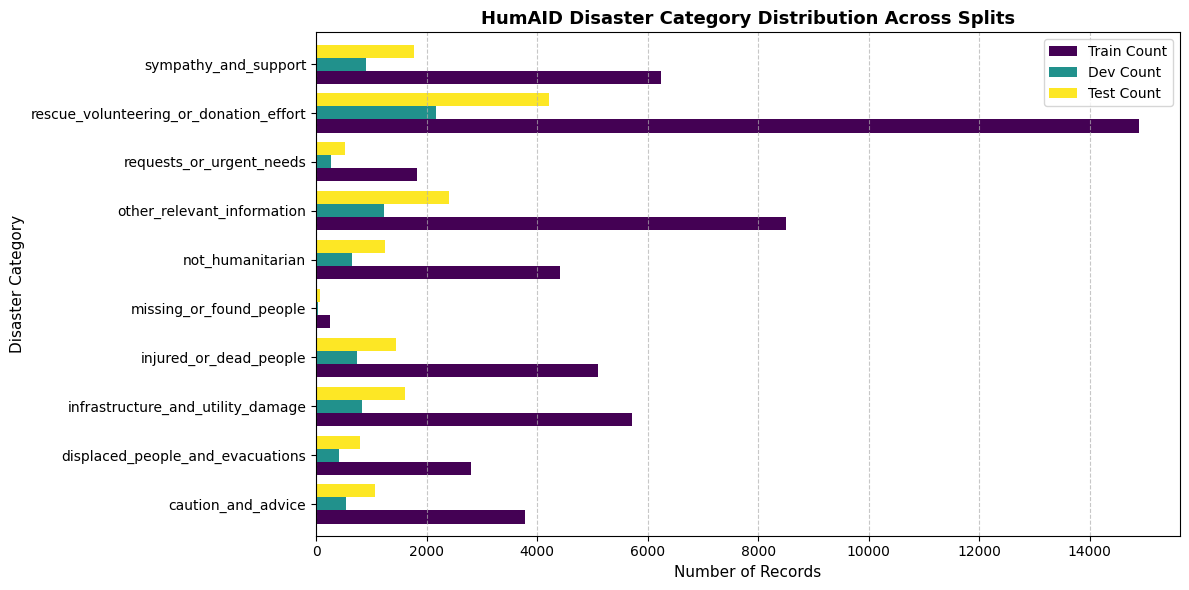

In [6]:
# 4. Class Distribution Comparison Table & Plot
dist_rows = []
for lbl in unique_train_labels:
    tr_count = int((df_train["class_label"] == lbl).sum())
    dv_count = int((df_dev["class_label"] == lbl).sum())
    ts_count = int((df_test["class_label"] == lbl).sum())
    dist_rows.append({
        "Category": lbl,
        "Train Count": tr_count,
        "Train %": round(tr_count / len(df_train) * 100, 2),
        "Dev Count": dv_count,
        "Dev %": round(dv_count / len(df_dev) * 100, 2),
        "Test Count": ts_count,
        "Test %": round(ts_count / len(df_test) * 100, 2),
    })

df_dist = pd.DataFrame(dist_rows)
display(df_dist)

# Plot class distributions
plot_df = df_dist.set_index("Category")[["Train Count", "Dev Count", "Test Count"]]
ax = plot_df.plot(kind="barh", figsize=(12, 6), width=0.8, colormap="viridis")
plt.title("HumAID Disaster Category Distribution Across Splits", fontsize=13, fontweight="bold")
plt.xlabel("Number of Records", fontsize=11)
plt.ylabel("Disaster Category", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


## 5. Text Preprocessing

Social-media crisis texts typically contain HTML entities (`&amp;`, `&lt;`), URLs, `@mentions`, and non-standard control characters.
We reuse `clean_text` and `LabelMapper` from `data/nlp/src/preprocessing.py`:
- Unescapes HTML entities.
- Strips non-informative URLs.
- Normalizes excess whitespace and control characters.
- Encodes labels to deterministic numerical IDs.


In [7]:
from data.nlp.src.preprocessing import clean_text, LabelMapper

# Demonstration of clean_text on raw crisis tweets
sample_raw_tweets = [
    "Powerful Ecuador quake kills at least 235 &amp; hundreds injured: https://t.co/xyz123 #EcuadorQuake",
    "RT @RedCross: Emergency shelter open at Central Gym! Free blankets &amp; water. http://redcross.org/relief",
    "Please RT: Two children missing near bridge after floods @police_dept #help",
]

print("--- Preprocessing Demonstration ---")
for raw in sample_raw_tweets:
    cleaned = clean_text(raw)
    print(f"RAW    : {raw}")
    print(f"CLEANED: {cleaned}\n")

# LabelMapper instantiation
mapper = LabelMapper(labels=unique_train_labels)
print(f"LabelMapper initialized with {len(mapper)} classes.")
print(f"Encoded 'requests_or_urgent_needs' -> ID {mapper.encode('requests_or_urgent_needs')}")
print(f"Decoded ID {mapper.encode('requests_or_urgent_needs')} -> '{mapper.decode(mapper.encode('requests_or_urgent_needs'))}'")


--- Preprocessing Demonstration ---
RAW    : Powerful Ecuador quake kills at least 235 &amp; hundreds injured: https://t.co/xyz123 #EcuadorQuake
CLEANED: Powerful Ecuador quake kills at least 235 & hundreds injured: #EcuadorQuake

RAW    : RT @RedCross: Emergency shelter open at Central Gym! Free blankets &amp; water. http://redcross.org/relief
CLEANED: RT @RedCross: Emergency shelter open at Central Gym! Free blankets & water.

RAW    : Please RT: Two children missing near bridge after floods @police_dept #help
CLEANED: Please RT: Two children missing near bridge after floods @police_dept #help

LabelMapper initialized with 10 classes.
Encoded 'requests_or_urgent_needs' -> ID 7
Decoded ID 7 -> 'requests_or_urgent_needs'


## 6. Tokenizer Preparation

We load the pretrained `DistilBertTokenizerFast` (`distilbert/distilbert-base-uncased`) and demonstrate tokenization, padding, truncation, and token decoding.


In [8]:
from transformers import AutoTokenizer

model_name = "distilbert/distilbert-base-uncased"
print(f"Loading pretrained tokenizer: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)

demo_message = "There is flooding near the bridge and people need rescue."
encoded = tokenizer(
    demo_message,
    padding="max_length",
    truncation=True,
    max_length=24,
    return_tensors="pt"
)

print(f'Demo Message        : "{demo_message}"')
print(f"Input IDs shape     : {encoded['input_ids'].shape}")
print(f"Attention Mask shape: {encoded['attention_mask'].shape}")
print(f"Input IDs           : {encoded['input_ids'][0].tolist()[:12]}")
print(f"Tokens              : {tokenizer.convert_ids_to_tokens(encoded['input_ids'][0][:12])}")


Loading pretrained tokenizer: distilbert/distilbert-base-uncased...


Demo Message        : "There is flooding near the bridge and people need rescue."
Input IDs shape     : torch.Size([1, 24])
Attention Mask shape: torch.Size([1, 24])
Input IDs           : [101, 2045, 2003, 9451, 2379, 1996, 2958, 1998, 2111, 2342, 5343, 1012]
Tokens              : ['[CLS]', 'there', 'is', 'flooding', 'near', 'the', 'bridge', 'and', 'people', 'need', 'rescue', '.']


## 7. Model Training Pipeline

The training pipeline is fully implemented in `data/nlp/src/train.py`. It integrates:
- **Pretrained Architecture:** `DistilBertForSequenceClassification`
- **Loss & Optimizer:** CrossEntropyLoss with AdamW and linear learning-rate warmup
- **Validation Model Selection:** Checkpoints are evaluated on the dev split at each epoch; the best model is selected based on `macro_f1`.
- **Test Split Isolation:** The test split is kept strictly untouched during training.

### How to Run Training:
1. **Full Training (Recommended via CLI):**
   ```bash
   python data/nlp/src/train.py --epochs 3 --batch_size 16 --lr 2e-5
   ```
2. **Smoke Test / Debug Run (Limits samples for quick verification):**
   ```bash
   python data/nlp/src/train.py --sample_limit 30 --epochs 1 --batch_size 8
   ```
3. **Resuming from Checkpoint:**
   ```bash
   python data/nlp/src/train.py --resume data/nlp/models/checkpoints/checkpoint-4
   ```

*Note: In this notebook, training is disabled by default to avoid long-running operations on CPU.*


In [9]:
# Training Execution Interface (Toggleable)
RUN_TRAINING_IN_NOTEBOOK = False
SMOKE_TEST_MODE = True  # If True, trains on 30 samples for fast verification

if RUN_TRAINING_IN_NOTEBOOK:
    from data.nlp.src.train import train_pipeline
    sample_limit = 30 if SMOKE_TEST_MODE else None
    epochs = 1 if SMOKE_TEST_MODE else 3
    batch_size = 8 if SMOKE_TEST_MODE else 16
    
    print(f"Launching training pipeline (Sample Limit: {sample_limit}, Epochs: {epochs})...")
    results = train_pipeline(
        epochs=epochs,
        batch_size=batch_size,
        sample_limit=sample_limit,
        run_test_eval=True
    )
    print("Training finished! Saved model to:", results["model_dir"])
else:
    print("Notebook training skipped (RUN_TRAINING_IN_NOTEBOOK is False).")
    print("Existing trained model weights are saved in: data/nlp/models/resqnet_distilbert/")


Notebook training skipped (RUN_TRAINING_IN_NOTEBOOK is False).
Existing trained model weights are saved in: data/nlp/models/resqnet_distilbert/


## 8. Model Evaluation

We evaluate the saved model on the held-out test split using the reusable evaluation module `data/nlp/src/evaluate.py`.
Metrics calculated:
- Overall Accuracy
- Macro Precision, Recall, and F1-Score (essential due to class imbalance)
- Weighted F1-Score
- Per-class metrics breakdown
- Confusion Matrix


[2026-10-16 17:17:15] [INFO] RESQNET.Evaluation: Loaded label mapper with 10 classes.


[2026-10-16 17:17:15] [INFO] RESQNET.Evaluation: Loading model and tokenizer from: data\nlp\models\resqnet_distilbert


Running evaluation on test split using model at: data\nlp\models\resqnet_distilbert ...


[2026-10-16 17:17:15] [INFO] RESQNET.Evaluation: Evaluating on device: cpu


[2026-10-16 17:17:15] [INFO] RESQNET.DataLoader: Loaded 50 valid samples from test.jsonl


...

[2026-10-16 17:17:15] [INFO] RESQNET.Evaluation: Saved evaluation metrics to: data\nlp\outputs\metrics\test_metrics.json


[2026-10-16 17:17:16] [INFO] RESQNET.Evaluation: Saved confusion matrix plot to: data\nlp\outputs\plots\test_confusion_matrix.png


[2026-10-16 17:17:16] [INFO] RESQNET.Evaluation: Saved per-class F1 plot to: data\nlp\outputs\plots\test_per_class_f1.png



TEST SPLIT PERFORMANCE METRICS
Accuracy         : 0.3600
Macro F1-Score   : 0.0963
Weighted F1-Score: 0.2198


,precision,recall,f1_score,support
caution_and_advice,0.000000,0.000000,0.000000,0
displaced_people_and_evacuations,0.000000,0.000000,0.000000,0
infrastructure_and_utility_damage,0.000000,0.000000,0.000000,1
injured_or_dead_people,0.369565,0.944444,0.531250,18
missing_or_found_people,0.000000,0.000000,0.000000,0
not_humanitarian,0.000000,0.000000,0.000000,1
other_relevant_information,0.000000,0.000000,0.000000,3
requests_or_urgent_needs,0.000000,0.000000,0.000000,1
rescue_volunteering_or_donation_effort,0.000000,0.000000,0.000000,16
sympathy_and_support,0.250000,0.100000,0.142857,10


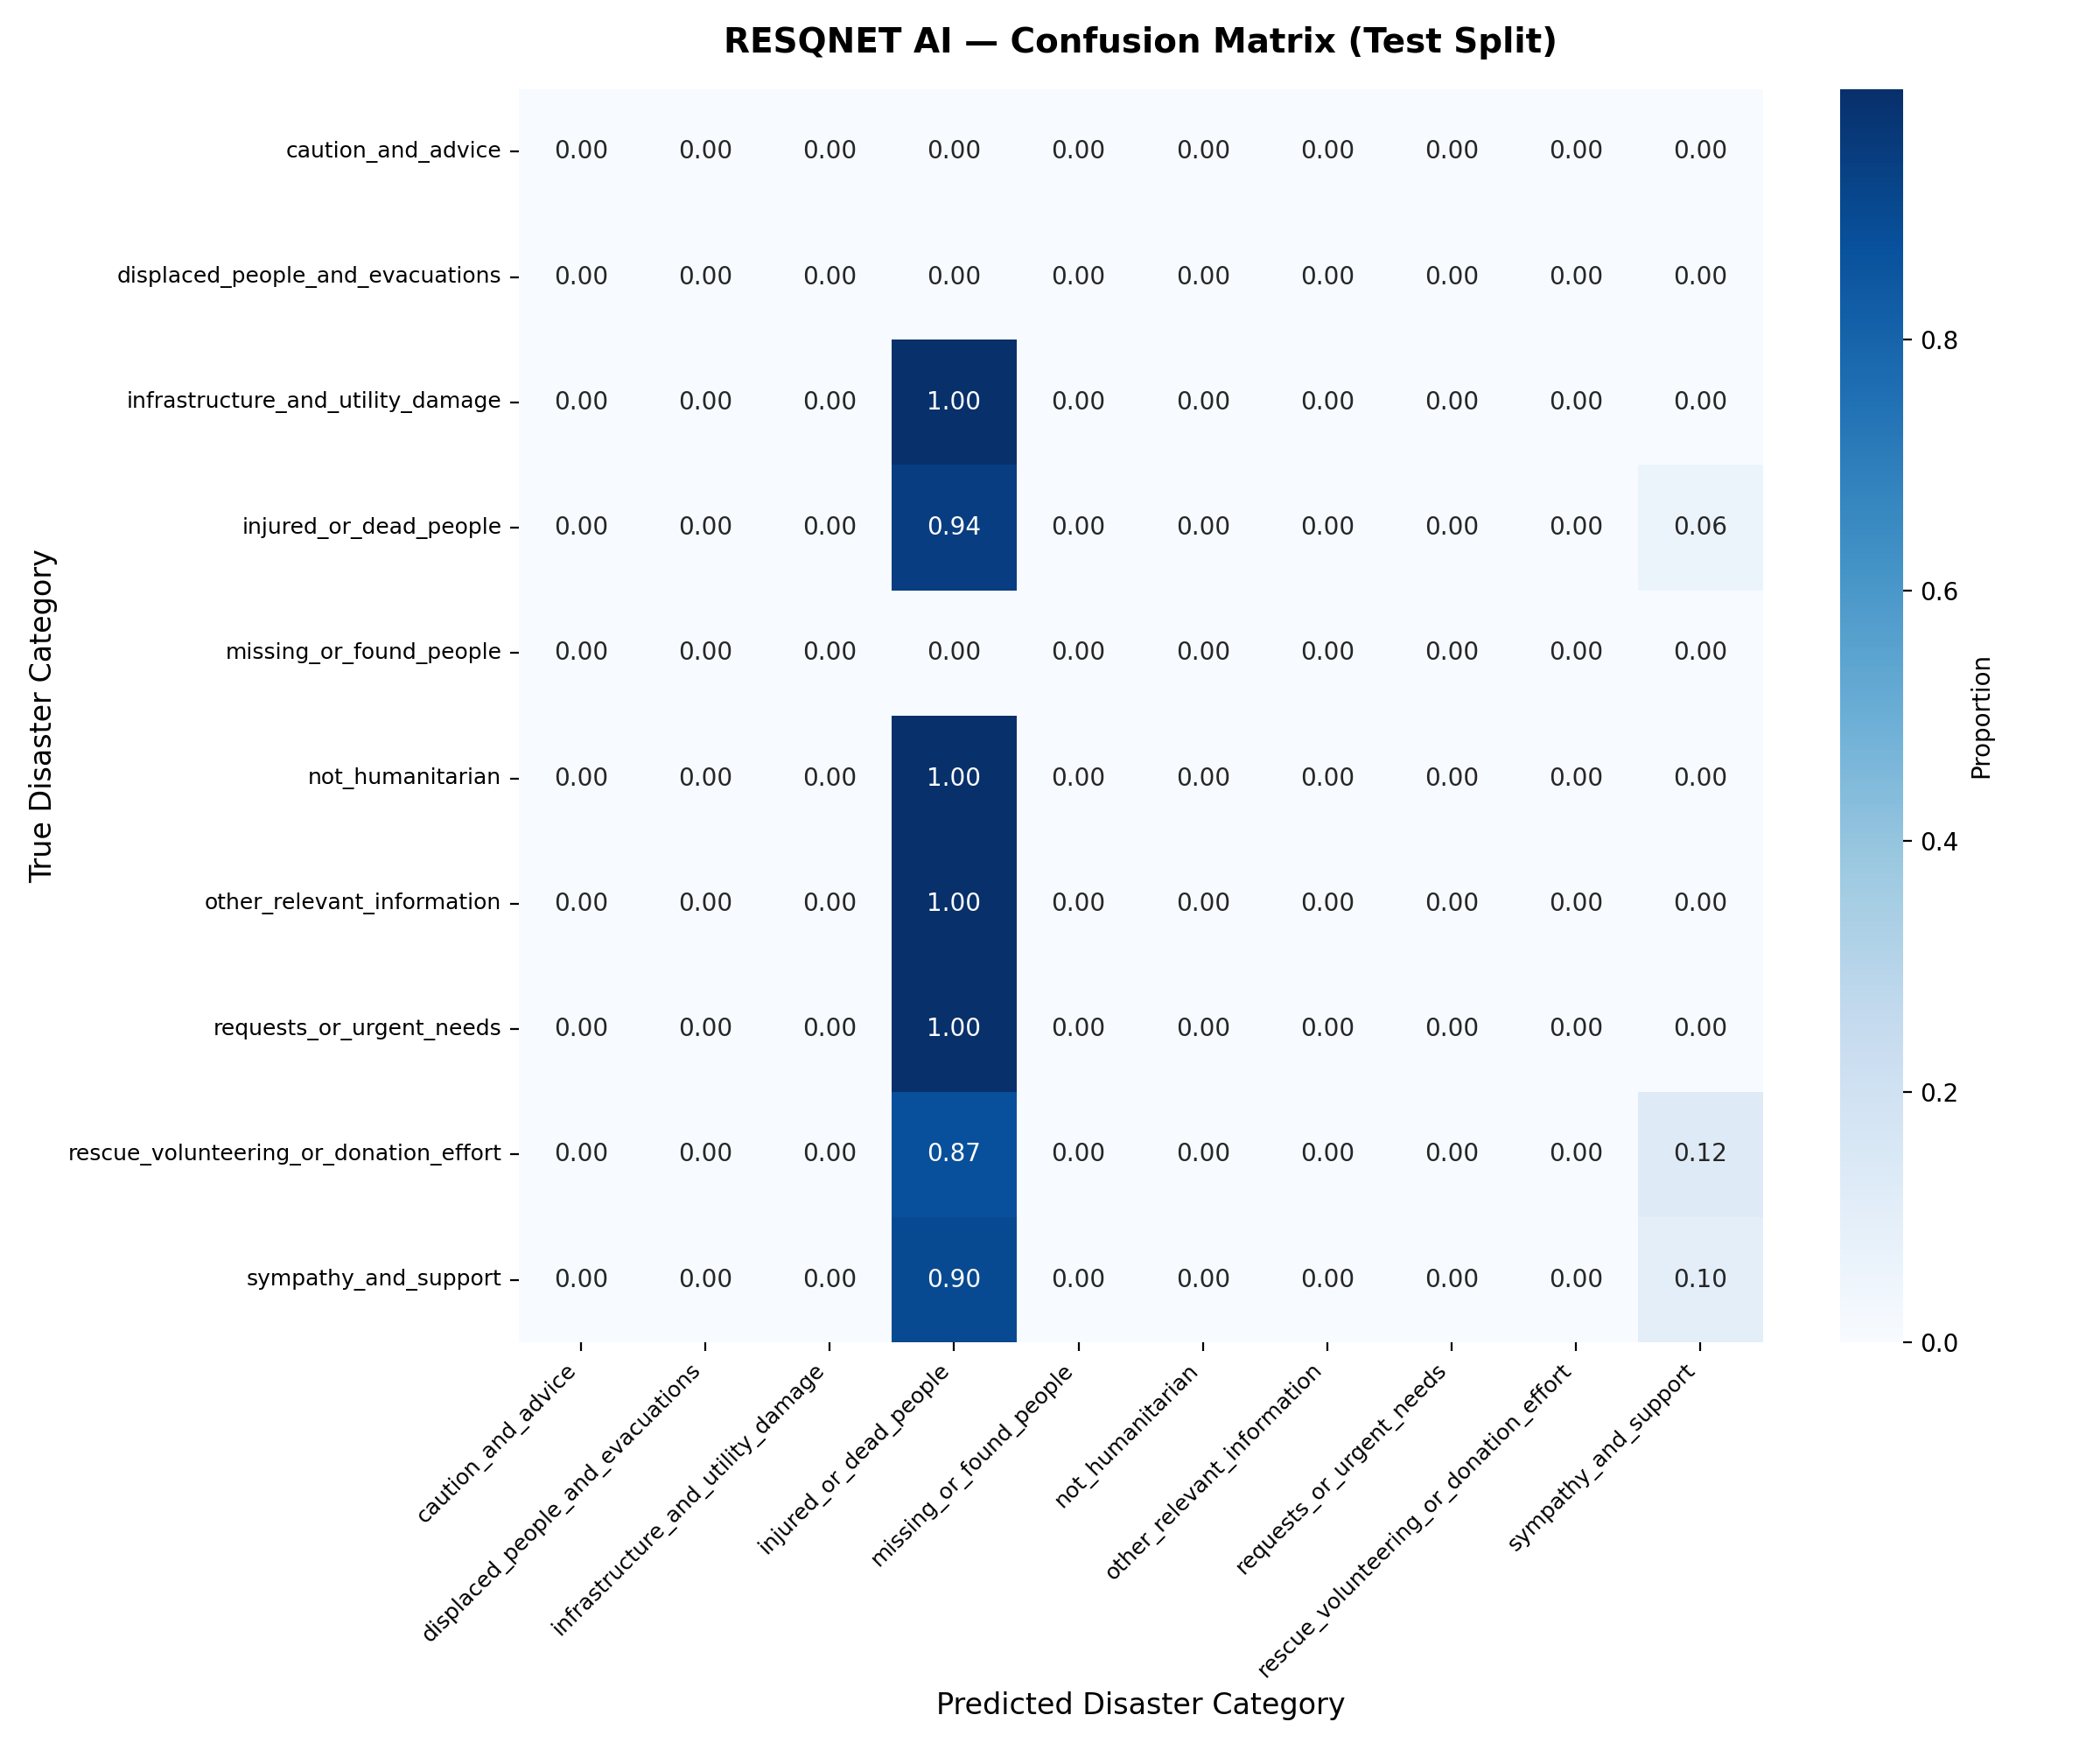

In [10]:
from data.nlp.src.evaluate import evaluate_saved_model
from IPython.display import Image, display

model_dir = Path("data/nlp/models/resqnet_distilbert")
assert model_dir.exists(), f"Model directory '{model_dir}' not found. Please train first."

print(f"Running evaluation on test split using model at: {model_dir} ...")
# Use sample_limit for quick notebook responsiveness; omit or set to None for all 15k test samples
test_eval = evaluate_saved_model(
    model_dir=model_dir,
    split_name="test",
    sample_limit=50
)

print("\n" + "=" * 60)
print("TEST SPLIT PERFORMANCE METRICS")
print("=" * 60)
print(f"Accuracy         : {test_eval['accuracy']:.4f}")
print(f"Macro F1-Score   : {test_eval['macro_f1']:.4f}")
print(f"Weighted F1-Score: {test_eval['weighted_f1']:.4f}")
print("=" * 60)

# Display per-class metrics
df_per_class = pd.DataFrame.from_dict(test_eval["per_class"], orient="index")
display(df_per_class)

# Display confusion matrix heatmap
cm_plot = Path("data/nlp/outputs/plots/test_confusion_matrix.png")
if cm_plot.exists():
    display(Image(filename=str(cm_plot)))


## 9. Sample Predictions & Coordinator Interface

We instantiate the production `ResqnetClassifier` from `data/nlp/src/inference.py` to classify realistic emergency messages.
Every prediction returns:
- Input message text
- Predicted disaster category
- Confidence score & full class probability distribution
- Mandatory RESQNET emergency safety disclaimer


In [11]:
from data.nlp.src.inference import ResqnetClassifier

classifier = ResqnetClassifier(
    model_dir="data/nlp/models/resqnet_distilbert",
    device="auto"
)

test_scenarios = [
    "There is flooding near the bridge and people need rescue.",
    "Major damage to Highway 101 overpass and power grid down across sector 3.",
    "Volunteers urgently needed at community center to package first-aid supplies.",
    "Two elderly residents trapped on roof due to rising flood waters on 4th street.",
    "Praying for everyone affected by the earthquake tonight, stay safe and strong.",
    "Emergency storm warning issued for coastal counties. Evacuate low-lying areas now."
]

print("=" * 75)
print("RESQNET AI — INCIDENT CLASSIFICATION PREDICTION INTERFACE")
print("=" * 75)

for msg in test_scenarios:
    pred = classifier.predict(msg, return_all_probabilities=True)
    print('\nInput Message     : "' + str(pred['input_text']) + '"')
    print(f"Predicted Category: {pred['predicted_category'].upper()}")
    print(f"Model Confidence  : {pred['confidence']:.2%}")
    print(f"Status            : {pred['status']}")
    print(f"Disclaimer        : {pred['disclaimer']}")
    
    # Top 3 probabilities
    sorted_probs = sorted(pred["all_probabilities"].items(), key=lambda x: x[1], reverse=True)[:3]
    print("Top Probabilities :")
    for cat, prob in sorted_probs:
        bar = "#" * int(prob * 25)
        print(f"   - {cat:38s}: {prob:6.2%} | {bar}")
    print("-" * 75)


[2026-10-16 17:17:16] [INFO] RESQNET.Inference: Loading RESQNET classifier from 'data\nlp\models\resqnet_distilbert' onto cpu...


[2026-10-16 17:17:16] [INFO] RESQNET.Inference: Classifier successfully loaded. Classes (10): ['caution_and_advice', 'displaced_people_and_evacuations', 'infrastructure_and_utility_damage', 'injured_or_dead_people', 'missing_or_found_people', 'not_humanitarian', 'other_relevant_information', 'requests_or_urgent_needs', 'rescue_volunteering_or_donation_effort', 'sympathy_and_support']


RESQNET AI — INCIDENT CLASSIFICATION PREDICTION INTERFACE

Input Message     : "There is flooding near the bridge and people need rescue."
Predicted Category: SYMPATHY_AND_SUPPORT
Model Confidence  : 11.90%
Status            : SUCCESS
Disclaimer        : RESQNET AI Automated NLP Prediction. Not a verified emergency report. This classification suggests the likely situational category of the text and does NOT confirm incident authenticity, verify coordinates, or dispatch units. All mission-critical emergency actions require human coordinator review.
Top Probabilities :
   - sympathy_and_support                  : 11.90% | ##
   - injured_or_dead_people                : 11.68% | ##
   - requests_or_urgent_needs              : 10.10% | ##
---------------------------------------------------------------------------

Input Message     : "Major damage to Highway 101 overpass and power grid down across sector 3."
Predicted Category: INJURED_OR_DEAD_PEOPLE
Model Confidence  : 12.40%
Status      


Input Message     : "Two elderly residents trapped on roof due to rising flood waters on 4th street."
Predicted Category: INJURED_OR_DEAD_PEOPLE
Model Confidence  : 11.95%
Status            : SUCCESS
Disclaimer        : RESQNET AI Automated NLP Prediction. Not a verified emergency report. This classification suggests the likely situational category of the text and does NOT confirm incident authenticity, verify coordinates, or dispatch units. All mission-critical emergency actions require human coordinator review.
Top Probabilities :
   - injured_or_dead_people                : 11.95% | ##
   - sympathy_and_support                  : 11.57% | ##
   - infrastructure_and_utility_damage     : 10.08% | ##
---------------------------------------------------------------------------

Input Message     : "Praying for everyone affected by the earthquake tonight, stay safe and strong."
Predicted Category: SYMPATHY_AND_SUPPORT
Model Confidence  : 12.59%
Status            : SUCCESS
Disclaimer     

## 10. Conclusion and Operational Limitations

### Summary of Accomplishments
1. **End-to-End NLP Pipeline:** Built a modular disaster classification pipeline fine-tuning DistilBERT on 76,484 HumAID records.
2. **Standardized Taxonomies:** Mapped and classified 10 distinct humanitarian operational categories.
3. **Decoupled Architecture:** Inference (`ResqnetClassifier`) is fully isolated from training and ready for integration with the FastAPI backend.
4. **Safety-First Design:** Clear disclaimers and validation protocols embedded into every prediction output.

### Known Limitations & Future Roadmap
| Capability | Current Status | Required Separate Component |
|---|---|---|
| **Category Classification** | Supported | Core DistilBERT multi-class classifier |
| **Incident Authenticity** | Not Supported | Requires cross-source verification, author reputation, and anomaly detection |
| **Geographic Coordinates** | Not Supported | Requires dedicated Named Entity Recognition (NER) & reverse-geocoding API |
| **Victim Count Estimation** | Not Supported | Requires numerical relation extraction module |
| **Duplicate Incident Deduplication**| Not Supported | Requires spatiotemporal clustering across incoming feeds |
| **Dispatch Decision-Making** | Not Supported | **Strictly Human-in-the-Loop:** Dispatch decisions remain human coordinator responsibility |

### Class Imbalance Considerations
- The class `missing_or_found_people` accounts for only **0.47%** (250 train samples).
- For production fine-tuning, consider class-weighted cross-entropy loss or focal loss to optimize minority class recall.
